# Mars Scout · cómo lo hizo NASA en Marte y cómo lo resolvimos nosotros

**Qué es esto.** Un rover simulado recibe el mapa real de Marte y tiene que decidir **qué lugares
visitar, en qué orden y por dónde ir**, sin quedarse sin energía y sin meterse en terreno peligroso.
Aquí lo comparamos con lo que **de verdad hizo Perseverance** en el cráter Jezero.

**Cómo usarlo.** No necesitas entender el código: cada sección tiene una explicación en texto y un
gráfico. Si quieres volver a ejecutarlo, usa *Ejecutar todo* (*Run All*). Dura unos 30 segundos.

> Todo lo que ves usa **datos reales** (ver sección 1). No hay terreno inventado en este documento.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11})

from marsmap import notebook_tools as nt

ctx = nt.load_context()
print(f"Terreno real cargado: {ctx.grid.shape[1]} x {ctx.grid.shape[0]} celdas de 200 m")
print(f"Sitios de muestras reales de Perseverance: {len(ctx.pois)}")
print(f"Waypoints reales del rover: {len(ctx.wp_sol)}  (sol {int(ctx.wp_sol.min())} a {int(ctx.wp_sol.max())})")
print(f"Sitio de aterrizaje (dato de NASA): {ctx.hab[0]:.5f} N, {ctx.hab[1]:.5f} E")

Terreno real cargado: 1061 x 1004 celdas de 200 m
Sitios de muestras reales de Perseverance: 22
Waypoints reales del rover: 708  (sol 13 a 2022)
Sitio de aterrizaje (dato de NASA): 18.44463 N, 77.45089 E


## 1. Los datos

| Qué | De dónde | ¿NASA? |
|---|---|---|
| **Relieve de Marte** (mapa de alturas, 200 m por celda) | MOLA–HRSC, publicado por USGS | **Parcial**: MOLA es de NASA (sonda MGS); HRSC es de la ESA (Mars Express) |
| **Sitios donde Perseverance tomó muestras** (22) | NASA/JPL, capa *Sampling Locations* | Sí |
| **Recorrido real del rover** (703 posiciones) y **aterrizaje** | NASA/JPL, capa *Rover Waypoints* | Sí |

Lo que **no** es un dato de NASA y es criterio nuestro: el *valor científico* de cada sitio (una regla
que da más puntos a la roca sedimentaria y a la que muestra alteración por agua), y los consumos de
energía y velocidades del rover, que son supuestos genéricos de demostración.

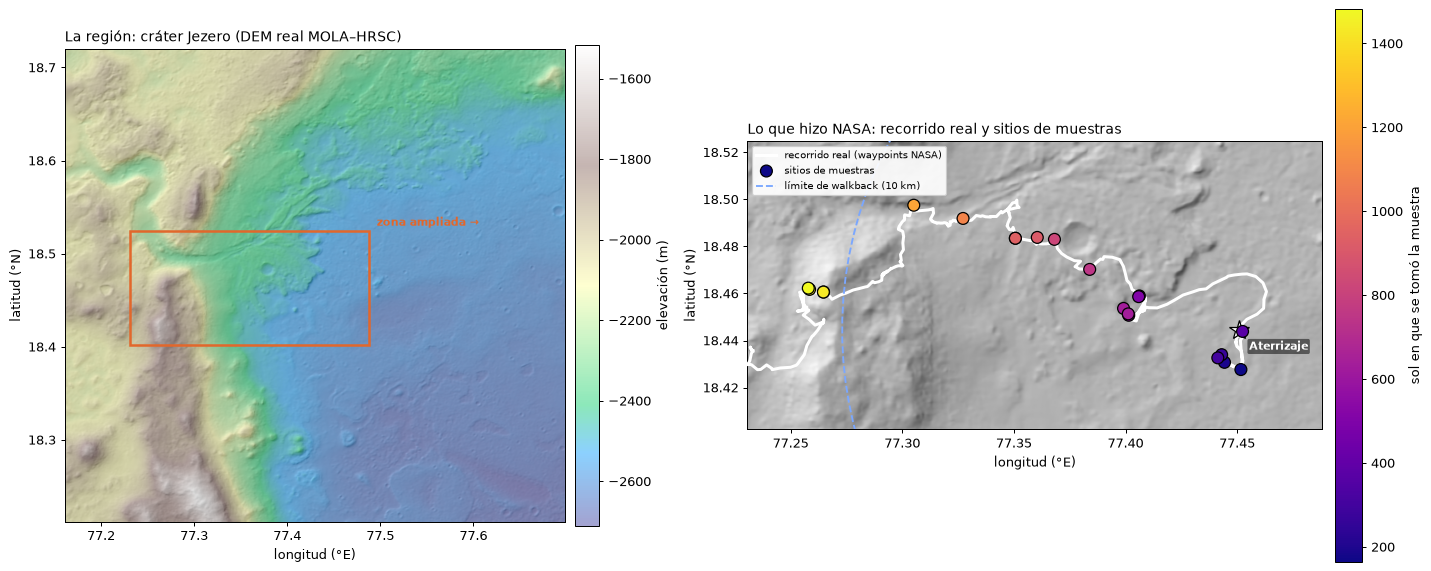

In [2]:
fig = nt.fig_nasa_overview(ctx); plt.show()

**Cómo leer el gráfico de la derecha.** La línea blanca es el camino **real** que recorrió Perseverance
desde que aterrizó (la estrella). Los puntos de colores son los sitios donde tomó muestras: más
oscuro = antes en la misión (sol = día marciano), más claro = después. La línea azul punteada es el
límite de **10 km** desde el aterrizaje (el «walkback»: hasta dónde se puede ir y poder volver).

## 2. Lo que hizo NASA

Perseverance tomó muestras en este orden (los sitios fuera de los 10 km son los del borde del cráter):

In [3]:
print(f"{'sol':>10}  {'sitio':<48}{'tipo':<12}{'km':>5}")
print("-" * 78)
for sol, name, stype, rock, km in nt.nasa_table(ctx):
    flag = "  (fuera del walkback)" if km > 10 else ""
    print(f"{sol:>10}  {name[:46]:<48}{stype[:10]:<12}{km:>5.1f}{flag}")

       sol  sitio                                           tipo           km
------------------------------------------------------------------------------
       164  Roubion (Polygon Valley)                        Atmospheri    1.0
 194 & 196  Montdenier + Montagnac (Artuby Ridge)           Rock Core     0.9
 262 & 271  Salette + Coulettes (South Séítah)              Rock Core     0.8
 298 & 337  Robine + Malay (South Séítah)                   Rock Core     0.9
 371 & 377  Ha'ahóni + Atsá (Octavia E. Butler Landing/Ch’  Rock Core     0.1
 490 & 495  Swift Run + Skyland (Fan Front)                 Rock Core     2.7
 509 & 516  Hazeltop + Bearwallow (Fan Front)               Rock Core     2.7
 575 & 579  Shuyak + Mageik (Fan Front)                     Rock Core     2.8
       631  Kukaklek (Fan Front)                            Rock Core     3.0
 634 & 639  Atmo Mountain + Crosswind Lake (Fan Front)      Regolith      2.8
       749  Melyn (Upper Fan)                               Roc

## 3. Cómo lo resolvimos nosotros

Lo hacemos en tres pasos. Cada uno resuelve un problema distinto.

### Paso 1 · Dónde se puede ir: el mapa de riesgo
Del mapa de alturas calculamos la **pendiente** de cada celda y la clasificamos con los umbrales que se
usan con Perseverance: menos de 10° es segura, de 10° a 15° tiene riesgo y más de 15° está bloqueada.

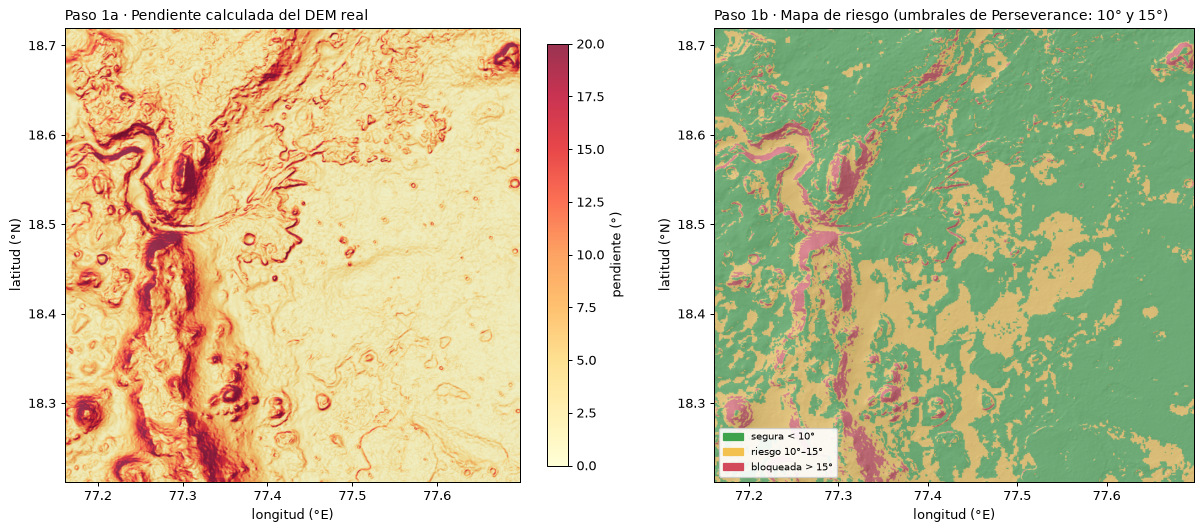

Segura: 65.6%   Riesgo: 29.3%   Bloqueada: 5.1%   (pendiente mediana 3.3°)


In [4]:
fig = nt.fig_terrain_layers(ctx); plt.show()
s = nt.terrain_summary(ctx)
print(f"Segura: {s['segura_pct']:.1f}%   Riesgo: {s['riesgo_pct']:.1f}%   Bloqueada: {s['bloqueada_pct']:.1f}%   "
      f"(pendiente mediana {s['pendiente_mediana']:.1f}°)")

### Paso 2 · Por dónde ir: rutas óptimas (algoritmo A*)
Entre dos puntos, A* encuentra el **camino más barato** (no el más corto: penaliza pendientes y terreno
de riesgo). Es un algoritmo exacto: garantiza que no existe uno mejor. Aquí, del aterrizaje al sitio más
lejano que aún queda dentro de los 10 km.

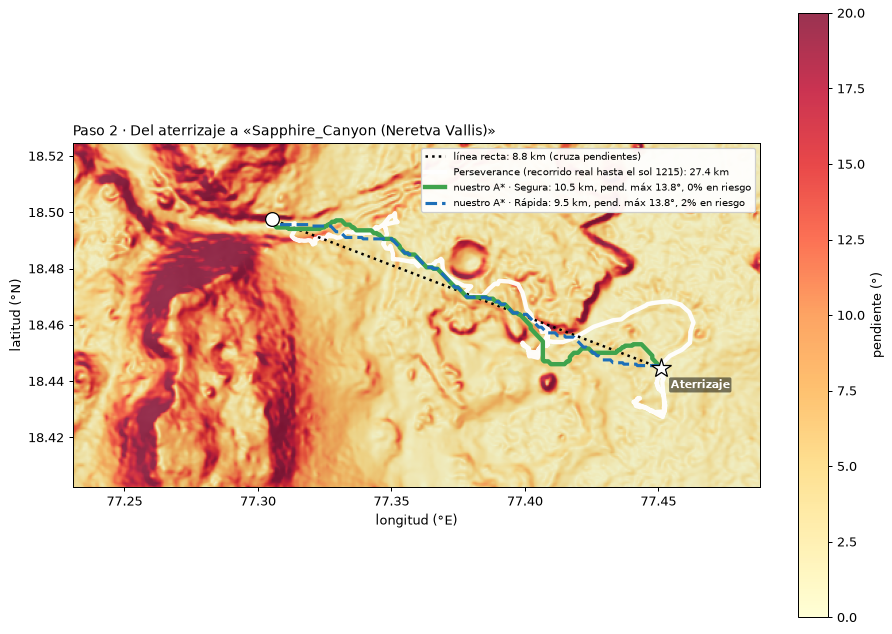

Por qué eligió esta ruta (explicación generada por el sistema):
  - El punto de destino está en pendiente mayor de 15° (o sin dato); la ruta llega al terreno transitable más cercano, a 30 m.
  - El 100% del recorrido está en terreno seguro (pendiente < 10°); la pendiente máxima es 13.8° (límite de bloqueo 15°).
  - La línea recta cruzaría 14 celdas bloqueadas (pendiente de hasta 23°, a 2.1 km del inicio); la ruta las evita con un desvío de 1.7 km (+20%).
  - Cruza 30 m de terreno de riesgo (10°–15°), donde se estima la mitad de velocidad.
  - Desnivel acumulado: +277 m / −65 m; tiempo estimado 105.5 h.


In [5]:
target = nt.route_target(ctx)
routes = nt.route_results(ctx, target)
fig = nt.fig_routes(ctx, target, routes); plt.show()
print("Por qué eligió esta ruta (explicación generada por el sistema):")
for line in routes["safe"].explanations:
    print("  -", line)

**Cómo leer el gráfico.** El fondo muestra la pendiente (rojo oscuro = muy empinado). La línea
punteada negra es la recta, que cruza terreno difícil. La línea verde es la ruta de A*, que **rodea lo
empinado** a cambio de unos cientos de metros más. La línea blanca gruesa es el recorrido **real** de
Perseverance *acumulado hasta ese sol*: incluye todo lo que hizo antes, no solo ir hasta ese sitio.

> Las rutas se ven «en escalera» porque el mapa es una cuadrícula de 200 m y solo permitimos 8
> direcciones. Es una limitación de la versión actual, no del algoritmo.

### Paso 3 · Qué visitar y en qué orden: el algoritmo genético
Aquí está el problema difícil. Hay 17 sitios dentro del alcance, y elegir **cuáles** visitar y **en qué
orden** con energía y tiempo limitados tiene millones de combinaciones (es un problema clásico llamado
*orienteering*). A* no puede resolverlo; un **algoritmo genético** sí puede explorar bien las opciones.

No devuelve una sola respuesta, sino **un abanico de misiones**: cada punto del gráfico es una misión
distinta, con su equilibrio entre ciencia, tiempo y energía.

El genético encontró 30 misiones distintas en 8.4 s
Sitios considerados: 16  ·  descartados por quedar a más de 10 km: 6
  - Silver Mountain (Crater Rim (Witch Hazel Hill)) está a 10.5 km del hábitat, más allá del límite de walkback de 10.0 km.
  - Green Gardens (Crater Rim (Witch Hazel Hill)) está a 10.5 km del hábitat, más allá del límite de walkback de 10.0 km.
  - Main River (Crater Rim (Witch Hazel Hill)) está a 10.9 km del hábitat, más allá del límite de walkback de 10.0 km.
  - Bell Island (Crater Rim (Witch Hazel Hill)) está a 10.9 km del hábitat, más allá del límite de walkback de 10.0 km.
  - Gallants (Crater Rim (Krokodillen)) está a 10.9 km del hábitat, más allá del límite de walkback de 10.0 km.
  - Sapphire_Canyon (Neretva Vallis) cae en terreno bloqueado (pendiente > 15°).


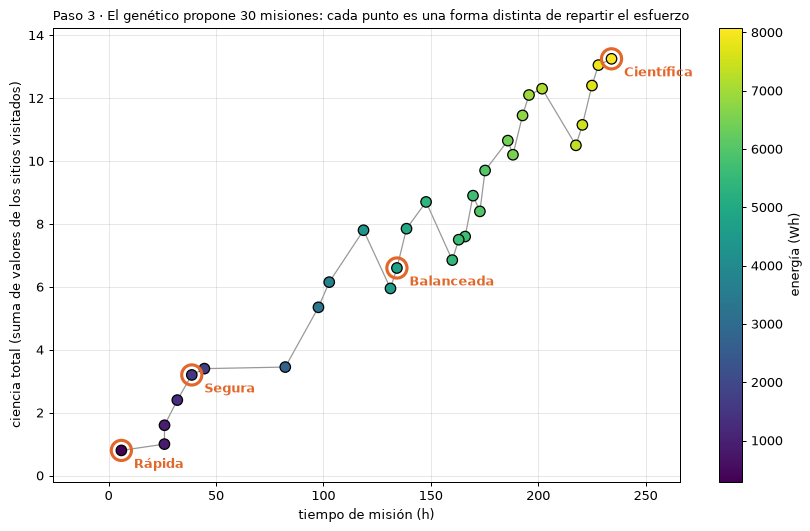

In [6]:
plan = nt.run_plan(ctx)
print(f"El genético encontró {len(plan.front)} misiones distintas en {plan.compute_ms / 1000:.1f} s")
print(f"Sitios considerados: {len(plan.pois)}  ·  descartados por quedar a más de 10 km: {len(plan.discarded)}")
for d in plan.discarded:
    print("  -", d.reason)
fig = nt.fig_pareto(plan); plt.show()

**Cómo leer el gráfico.** Cuanto más a la derecha, más tiempo; cuanto más arriba, más ciencia. No hay
una «mejor» misión: hay un **compromiso**. La *Rápida* va a un solo sitio. La *Científica* visita casi
todo. La *Balanceada* es el punto de equilibrio. Quien planifica elige según su prioridad (en la
aplicación web esto se hace con controles deslizantes).

> En este terreno **ninguna misión cruza zonas de riesgo** (el suelo del cráter es mayormente llano
> y A* las rodea), por eso no mostramos una misión «Segura»: sería solo un desempate arbitrario.

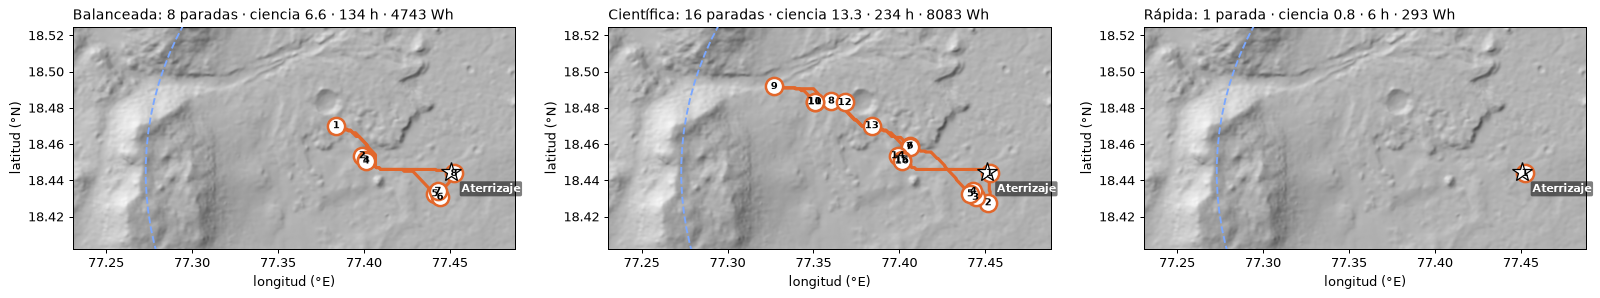

In [7]:
fig = nt.fig_missions(ctx, plan); plt.show()

In [8]:
mission = plan.mission(plan.named["balanced"])
print("La misión Balanceada, explicada (primeras líneas):")
for line in plan.explanations[mission.mission_id][:5]:
    print("  -", line)

La misión Balanceada, explicada (primeras líneas):
  - Visita Melyn (Upper Fan) (ciencia 0.90, estudio de 2.0 h) a 4.7 km del hábitat. Quitarlo ahorraría 1125 Wh y 34.3 h, pero perdería 0.90 de ciencia.
  - Visita Kukaklek (Fan Front) (ciencia 0.90, estudio de 2.0 h) a 1.7 km de Melyn (Upper Fan). Quitarlo ahorraría 161 Wh y 3.2 h, pero perdería 0.90 de ciencia.
  - Visita Atmo Mountain + Crosswind Lake (Fan Front) (ciencia 0.65, estudio de 3.0 h) a 0.2 km de Kukaklek (Fan Front). Quitarlo ahorraría 180 Wh y 3.0 h, pero perdería 0.65 de ciencia.
  - Visita Shuyak + Mageik (Fan Front) (ciencia 0.95, estudio de 4.0 h) a 0.0 km de Atmo Mountain + Crosswind Lake (Fan Front). Quitarlo ahorraría 240 Wh y 4.0 h, pero perdería 0.95 de ciencia.
  - Visita Robine + Malay (South Séítah) (ciencia 0.80, estudio de 4.0 h) a 2.7 km de Shuyak + Mageik (Fan Front). Quitarlo ahorraría 241 Wh y 4.0 h, pero perdería 0.80 de ciencia.


## 4. Comparación: NASA vs nosotros

La pregunta justa: **para visitar los mismos sitios, ¿qué orden gasta menos?** Tomamos las 16 paradas de
nuestra misión científica y comparamos dos órdenes, midiendo los dos con el **mismo modelo de terreno**:

- el orden **real** en que NASA tomó esas muestras (por fecha), y
- el orden que **nosotros** calculamos.

Mismo conjunto de 16 paradas, ida y vuelta al aterrizaje:

                               distancia    tiempo     energía
Orden real de NASA               21.2 km    259 h     8776 Wh
Nuestro orden                    18.7 km    234 h     8083 Wh
Ahorro                              12 %      10 %         8 %

Contexto real: entre la muestra del sol 164 y la del sol 1088, el odómetro de
Perseverance avanzó 23.3 km (incluye desvíos, exploración y maniobras).


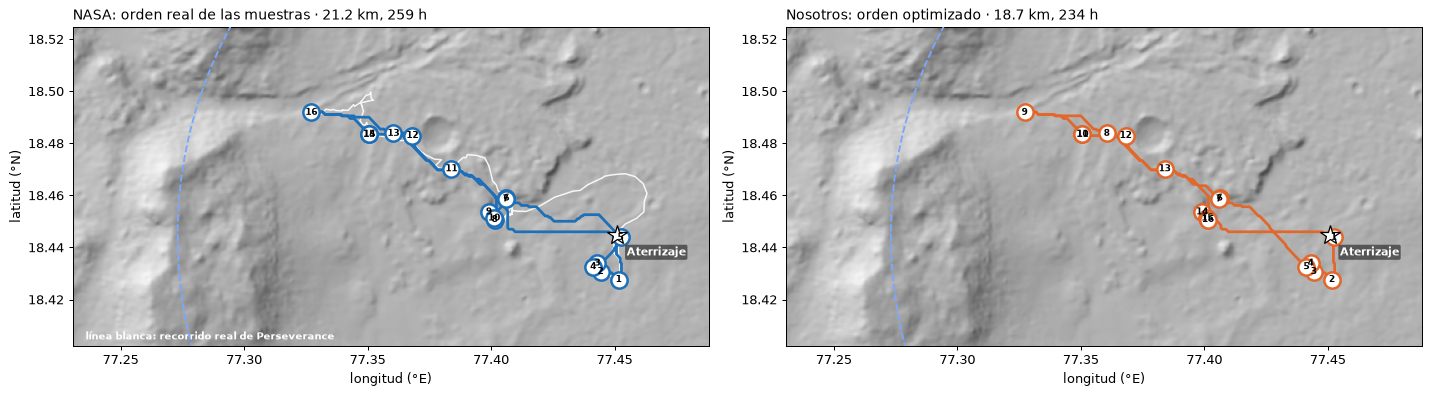

In [9]:
cmp = nt.nasa_vs_ours(ctx, plan)
n, o = cmp["nasa"], cmp["ours"]
print(f"Mismo conjunto de {len(cmp['ours_seq'])} paradas, ida y vuelta al aterrizaje:\n")
print(f"{'':<28}{'distancia':>12}{'tiempo':>10}{'energía':>12}")
print(f"{'Orden real de NASA':<28}{n.distance_m / 1000:>9.1f} km{n.time_h:>7.0f} h{n.energy_wh:>9.0f} Wh")
print(f"{'Nuestro orden':<28}{o.distance_m / 1000:>9.1f} km{o.time_h:>7.0f} h{o.energy_wh:>9.0f} Wh")
print(f"{'Ahorro':<28}{100 * (1 - o.distance_m / n.distance_m):>10.0f} %{100 * (1 - o.time_h / n.time_h):>8.0f} %{100 * (1 - o.energy_wh / n.energy_wh):>10.0f} %")
print(f"\nContexto real: entre la muestra del sol {cmp['sol_first']} y la del sol {cmp['sol_last']}, el odómetro de")
print(f"Perseverance avanzó {cmp['nasa_odometer_km']:.1f} km (incluye desvíos, exploración y maniobras).")
fig = nt.fig_nasa_vs_ours(ctx, plan, cmp); plt.show()

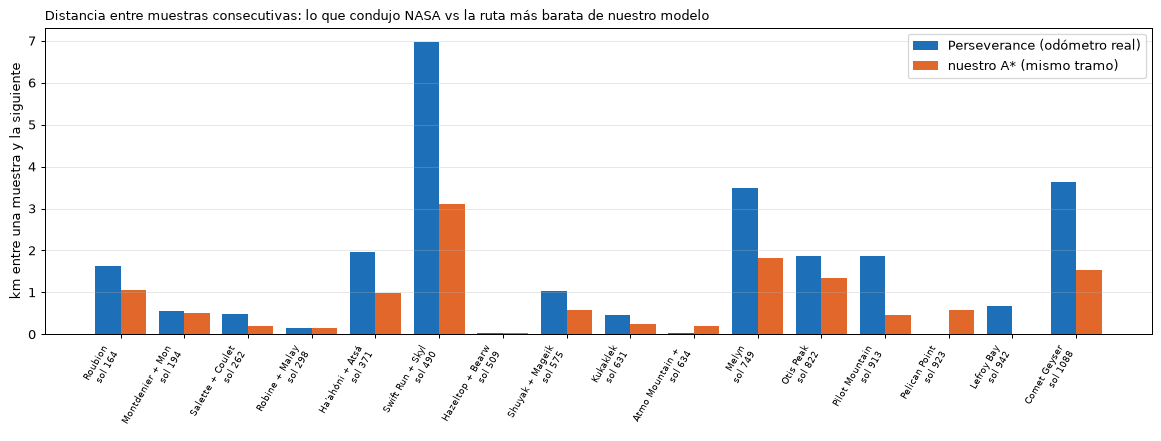

In [10]:
fig = nt.fig_legs(cmp); plt.show()

**Lo que sí dice esta comparación:** con el mismo modelo, conocer **todos los objetivos desde el
principio** permite un orden más corto. Es justo lo que hace un planificador, y NASA no podía hacerlo
así porque los objetivos fueron apareciendo durante años.

**Lo que NO dice, y hay que ser honestos:**
- **No dice que NASA lo hiciera mal.** Su orden respondió a las fases de la misión, a objetivos que
  fueron surgiendo y a la seguridad del rover, no a minimizar distancia.
- Las distancias de NASA en el gráfico de barras son del **odómetro**: incluyen desvíos, así que no son
  comparables punto a punto con nuestra ruta más barata. Sirven como contexto, no como medida exacta.
- Nuestro modelo **no ve los peligros que el satélite no muestra** (arena blanda, rocas pequeñas), y
  NASA sí los enfrenta. Esa parte todavía no está construida.
- Falta comparar también nuestras **rutas** con el recorrido real tramo a tramo.

## 5. Pruebas de que el algoritmo funciona

Dos comprobaciones, con datos reales, que se ejecutan aquí mismo:

In [11]:
res = nt.check_astar_vs_dijkstra(ctx, n=10)
ok = all(abs(a - b) < 1e-6 for a, b, _, _ in res)
print("A* contra Dijkstra (método exhaustivo), 10 pares de puntos al azar sobre terreno real:")
print(f"  {'✓' if ok else '✗'} mismo costo en {sum(abs(a - b) < 1e-6 for a, b, _, _ in res)}/10 casos")
print(f"  A* exploró {sum(r[2] for r in res):,} celdas; Dijkstra {sum(r[3] for r in res):,} "
      f"({sum(r[3] for r in res) / sum(r[2] for r in res):.1f}x más)\n")
print("Genético contra fuerza bruta (probar TODOS los órdenes) con 8 sitios reales:")
for budget, ga, exact in nt.check_ga_vs_bruteforce(ctx):
    mark = "✓" if abs(ga - exact) < 1e-6 else "✗"
    print(f"  {mark} presupuesto {budget:,.0f} Wh: genético {ga:.2f}  ·  óptimo exacto {exact:.2f}")

A* contra Dijkstra (método exhaustivo), 10 pares de puntos al azar sobre terreno real:
  ✓ mismo costo en 10/10 casos
  A* exploró 2,192,632 celdas; Dijkstra 4,824,875 (2.2x más)

Genético contra fuerza bruta (probar TODOS los órdenes) con 8 sitios reales:


  ✓ presupuesto 6,000 Wh: genético 5.95  ·  óptimo exacto 5.95
  ✓ presupuesto 9,000 Wh: genético 6.90  ·  óptimo exacto 6.90


## 6. Qué demuestra este trabajo y qué no

**Demuestra:**
1. Con datos reales de NASA, el sistema produce misiones **válidas**: no pasan por terreno bloqueado y
   respetan energía, tiempo y el límite de 10 km.
2. A* es **exacto** y el genético **encuentra el óptimo** donde se puede comprobar (8 sitios).
3. Para el mismo conjunto de sitios, un orden planificado es **más corto** que el orden histórico.

**No demuestra todavía:**
1. Que nuestro modelo de costos refleje la realidad: los umbrales y pesos son los de la literatura, sin
   calibrar contra los datos de conducción reales.
2. Nada sobre **peligros ocultos** (lo que el satélite no ve): es la siguiente etapa.
3. El **valor científico** de cada sitio es una regla nuestra, no una valoración de NASA.
4. La energía y velocidad del rover son **supuestos genéricos**, no los de Perseverance.

*Fuentes de datos: DEM MOLA–HRSC (NASA/ESA, vía USGS) y capas públicas de Mars 2020 (NASA/JPL, mars.nasa.gov).*